In [1]:
import numpy as np
import matplotlib.pyplot as plt
import cv2

## Tấn Hiệp – Demo 5: Xoay ảnh (warping ngược, nội suy)

Bám slide 62–67 (Computer_Vision 18):

1. **Ma trận xoay thuần nhất 3×3 quanh tâm** $(c_x, c_y) = \left(\frac{w-1}{2}, \frac{h-1}{2}\right)$:
   $M = T(c_x, c_y)\; R(\theta)\; T(-c_x, -c_y)$, tức là dịch tâm về gốc → xoay → dịch về tâm.
   Trục y của ảnh hướng xuống, nên để góc dương xoay **ngược chiều kim đồng hồ** trên màn hình, R dùng
   $\begin{bmatrix}\cos\theta & \sin\theta\\ -\sin\theta & \cos\theta\end{bmatrix}$.
2. **Warping ngược:** với mỗi pixel đích $(x', y')$, tính toạ độ nguồn $(x, y, 1) = M^{-1}(x', y', 1)$, nên ảnh đích không có lỗ.
3. **Lấy mẫu tại toạ độ thực $(x, y)$:**
   - Gần nhất: làm tròn về pixel gần nhất.
   - Song tuyến (slide 66), nội suy hai lần, theo x rồi theo y:
     $R_1 = (1-\delta_x)Q_{11} + \delta_x Q_{21}$, $R_2 = (1-\delta_x)Q_{12} + \delta_x Q_{22}$, $P = (1-\delta_y)R_1 + \delta_y R_2$.

In [2]:
def tao_ban_co(kich_thuoc=200, o=25, sang=220, toi=60):
    ban_co = np.zeros((kich_thuoc, kich_thuoc), dtype=np.uint8)
    for y in range(kich_thuoc):
        for x in range(kich_thuoc):
            if (x // o + y // o) % 2 == 0:
                ban_co[y, x] = sang
            else:
                ban_co[y, x] = toi
    return ban_co


def ma_tran_xoay(goc_do, cx, cy):
    t = np.deg2rad(goc_do)
    c, s = np.cos(t), np.sin(t)

    T_ve_goc = np.array([[1, 0, -cx],
                         [0, 1, -cy],
                         [0, 0, 1]])
    R = np.array([[c, s, 0],
                  [-s, c, 0],
                  [0, 0, 1]])
    T_ve_tam = np.array([[1, 0, cx],
                         [0, 1, cy],
                         [0, 0, 1]])

    return T_ve_tam @ R @ T_ve_goc


ban_co = tao_ban_co()
h, w = ban_co.shape
cx, cy = (w - 1) / 2, (h - 1) / 2

M = ma_tran_xoay(30, cx, cy)
tam_sau_xoay = M @ np.array([cx, cy, 1])
print("Ma trận xoay 30°:\n", np.round(M, 3))
print(f"Tâm trước khi xoay: ({cx:.2f}, {cy:.2f})")
print(f"Tâm sau khi xoay:  ({tam_sau_xoay[0]:.2f}, {tam_sau_xoay[1]:.2f})")
print("Tâm không đổi:", np.allclose(tam_sau_xoay[:2], [cx, cy]))

Ma trận xoay 30°:
 [[  0.866   0.5   -36.42 ]
 [ -0.5     0.866  63.08 ]
 [  0.      0.      1.   ]]
Tâm trước khi xoay: (99.50, 99.50)
Tâm sau khi xoay:  (99.50, 99.50)
Tâm không đổi: True


In [3]:
def lay_gan_nhat(anh, x, y):
    h, w = anh.shape
    xi = int(np.round(x))
    yi = int(np.round(y))
    if xi < 0 or xi >= w or yi < 0 or yi >= h:
        return 0.0
    return float(anh[yi, xi])


def lay_song_tuyen(anh, x, y):
    h, w = anh.shape
    eps = 1e-6
    if x < -eps or x > w - 1 + eps or y < -eps or y > h - 1 + eps:
        return 0.0

    x = min(max(x, 0.0), w - 1)
    y = min(max(y, 0.0), h - 1)

    x0 = int(np.floor(x))
    y0 = int(np.floor(y))
    x1 = min(x0 + 1, w - 1)
    y1 = min(y0 + 1, h - 1)

    dx = x - x0
    dy = y - y0

    Q11 = float(anh[y0, x0])
    Q21 = float(anh[y0, x1])
    Q12 = float(anh[y1, x0])
    Q22 = float(anh[y1, x1])

    R1 = (1 - dx) * Q11 + dx * Q21
    R2 = (1 - dx) * Q12 + dx * Q22
    P = (1 - dy) * R1 + dy * R2
    return P


def xoay_anh(anh, goc_do, kieu="song_tuyen"):
    if kieu == "gan_nhat":
        lay_mau = lay_gan_nhat
    elif kieu == "song_tuyen":
        lay_mau = lay_song_tuyen
    else:
        raise ValueError("kieu phải là 'gan_nhat' hoặc 'song_tuyen'")

    h, w = anh.shape
    M = ma_tran_xoay(goc_do, (w - 1) / 2, (h - 1) / 2)
    M_nguoc = np.linalg.inv(M)

    ket_qua = np.zeros((h, w), dtype=np.float64)
    for y_dich in range(h):
        for x_dich in range(w):
            x_nguon, y_nguon, _ = M_nguoc @ np.array([x_dich, y_dich, 1.0])
            ket_qua[y_dich, x_dich] = lay_mau(anh, x_nguon, y_nguon)

    return np.clip(np.round(ket_qua), 0, 255).astype(np.uint8)

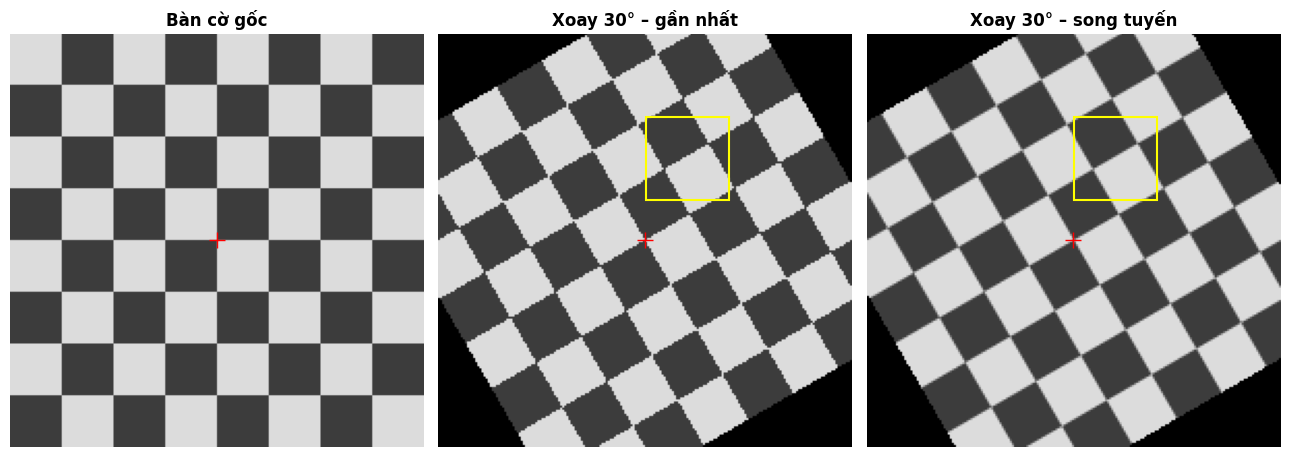

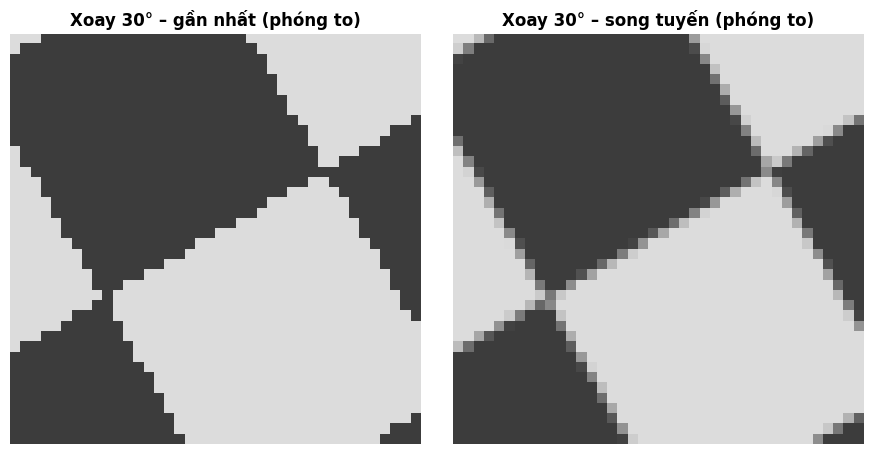

In [4]:
goc = 30
anh_gan_nhat = xoay_anh(ban_co, goc, "gan_nhat")
anh_song_tuyen = xoay_anh(ban_co, goc, "song_tuyen")

anh_list = [ban_co, anh_gan_nhat, anh_song_tuyen]
ten_list = ["Bàn cờ gốc", f"Xoay {goc}° – gần nhất", f"Xoay {goc}° – song tuyến"]

y1, y2, x1, x2 = 40, 80, 100, 140

plt.figure(figsize=(13, 4.5))
for i in range(3):
    plt.subplot(1, 3, i + 1)
    plt.imshow(anh_list[i], cmap="gray", vmin=0, vmax=255)
    plt.plot(cx, cy, "r+", markersize=12)
    if i > 0:
        plt.gca().add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1,
                                          fill=False, edgecolor="yellow", linewidth=1.5))
    plt.title(ten_list[i], fontsize=12, fontweight="bold")
    plt.axis("off")
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 4.5))
for i in range(1, 3):
    plt.subplot(1, 2, i)
    plt.imshow(anh_list[i][y1:y2, x1:x2], cmap="gray", vmin=0, vmax=255,
               interpolation="nearest")
    plt.title(ten_list[i] + " (phóng to)", fontsize=12, fontweight="bold")
    plt.axis("off")
plt.tight_layout()
plt.show()

In [5]:
M_cv = cv2.getRotationMatrix2D((cx, cy), goc, 1.0)
cv_gan_nhat = cv2.warpAffine(ban_co, M_cv, (w, h), flags=cv2.INTER_NEAREST)
cv_song_tuyen = cv2.warpAffine(ban_co, M_cv, (w, h), flags=cv2.INTER_LINEAR)

print("Ma trận tự xây == OpenCV:", np.allclose(ma_tran_xoay(goc, cx, cy)[:2], M_cv))
print("Gần nhất   - sai lệch TB so với OpenCV:",
      round(np.mean(np.abs(anh_gan_nhat.astype(int) - cv_gan_nhat)), 4))
print("Song tuyến - sai lệch TB so với OpenCV:",
      round(np.mean(np.abs(anh_song_tuyen.astype(int) - cv_song_tuyen)), 4))

Ma trận tự xây == OpenCV: True
Gần nhất   - sai lệch TB so với OpenCV: 0.0
Song tuyến - sai lệch TB so với OpenCV: 0.6021


In [6]:
anh_sang = np.full((200, 200), 200, dtype=np.uint8)

for goc_thu, k in [(0, 0), (90, 1), (180, 2), (270, 3), (360, 0)]:
    for kieu in ["gan_nhat", "song_tuyen"]:
        kq_sang = xoay_anh(anh_sang, goc_thu, kieu)
        kq_ban_co = xoay_anh(ban_co, goc_thu, kieu)
        so_den = int(np.sum(kq_sang == 0))
        dung_rot90 = np.array_equal(kq_ban_co, np.rot90(ban_co, k))
        print(f"{goc_thu:3d}° {kieu:10s}: {so_den} pixel đen, "
              f"bàn cờ == np.rot90(k={k}): {dung_rot90}")

  0° gan_nhat  : 0 pixel đen, bàn cờ == np.rot90(k=0): True
  0° song_tuyen: 0 pixel đen, bàn cờ == np.rot90(k=0): True
 90° gan_nhat  : 0 pixel đen, bàn cờ == np.rot90(k=1): True
 90° song_tuyen: 0 pixel đen, bàn cờ == np.rot90(k=1): True
180° gan_nhat  : 0 pixel đen, bàn cờ == np.rot90(k=2): True
180° song_tuyen: 0 pixel đen, bàn cờ == np.rot90(k=2): True
270° gan_nhat  : 0 pixel đen, bàn cờ == np.rot90(k=3): True
270° song_tuyen: 0 pixel đen, bàn cờ == np.rot90(k=3): True
360° gan_nhat  : 0 pixel đen, bàn cờ == np.rot90(k=0): True
360° song_tuyen: 0 pixel đen, bàn cờ == np.rot90(k=0): True


In [7]:
cv2.imwrite("../images/xoay_gan_nhat.png", anh_gan_nhat)
cv2.imwrite("../images/xoay_song_tuyen.png", anh_song_tuyen)
print("Đã lưu: ../images/xoay_gan_nhat.png, ../images/xoay_song_tuyen.png")

Đã lưu: ../images/xoay_gan_nhat.png, ../images/xoay_song_tuyen.png


## KT3 – hough_multiscale